# Lab 1 — Intro to Behavioral TV Data
Name: Chen Xinwei | Group: KM-42

## Setup

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

for table in (programs, viewings):
    table["start_ts"] = pd.to_datetime(table["start_ts"])
    table["end_ts"] = pd.to_datetime(table["end_ts"])
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"]).dt.normalize()
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"]).dt.normalize()
OCT = (daily_weights["broadcast_date"] >= "2024-10-01") & (daily_weights["broadcast_date"] <= "2024-10-31")
dw = daily_weights.loc[OCT].copy()
persons = dw.loc[dw.resp_type.isin(["R", "L"])].copy()
homes = dw.loc[dw.resp_type.eq("H")].copy()
person_ids = persons.respondent_id.unique()
home_ids = homes.respondent_id.unique()
ages = (viewer_attributes.loc[viewer_attributes.attr_id.eq(300), ["respondent_id", "value"]]
        .drop_duplicates("respondent_id").rename(columns={"value": "age"}))
sex_codes = viewer_attributes.loc[viewer_attributes.attr_id.isin([201, 202]), ["respondent_id", "attr_id"]]
sex_names = (sex_codes.merge(attributes[["attr_id", "attr_name"]].drop_duplicates("attr_id"), on="attr_id", how="left")
             .assign(sex=lambda d: np.where(d.attr_id.eq(201), "M", "W"))
             [["respondent_id", "sex"]].drop_duplicates("respondent_id"))
demog = ages.merge(sex_names, on="respondent_id", how="left")
persons = persons.merge(demog, on="respondent_id", how="left", validate="many_to_one")
monthly = persons.groupby("respondent_id", as_index=False).agg(month_weight=("weight", "mean"),
                                                               age=("age", "first"), sex=("sex", "first"))
assert monthly.age.notna().all() and monthly.sex.notna().all(), "Check numeric age/sex attributes"
print("Attribute code examples:")
display(attributes.loc[attributes.attr_id.isin([201, 202, 300]), ["attr_id", "attr_name", "value_type"]])

C:\Users\vivia\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 5.90M/5.90M [00:01<00:00, 4.83MB/s]

Extracting files...


Attribute code examples:


,attr_id,attr_name,value_type
4,201,Male,flag
5,202,Female,flag
6,300,Age in years,numeric


## Task 1.1 — Panel and universe

**Question:** How many telecasts, distinct programs and networks are in `programs`? How many households and persons were in-tab at least once in October (use `daily_weights`)? Why does `viewer_attributes` list a few more? On an average day, how many are in-tab, and how many US households and persons do their weights add up to?


In [2]:
print("Telecasts:", programs.telecast_id.nunique())
print("Programs:", programs.program_name.nunique())
print("Networks:", programs.network_code.nunique())
print("Households in panel:", homes.respondent_id.nunique())
print("Persons in panel:", persons.respondent_id.nunique())
print("Households in-tab, average day:", round(homes.groupby("broadcast_date").respondent_id.nunique().mean(), 1))
print("Persons in-tab, average day:", round(persons.groupby("broadcast_date").respondent_id.nunique().mean(), 1))
print("US TV households represented, average day (M):", round(homes.groupby("broadcast_date").weight.sum().mean()/1e6, 2))
print("US persons represented, average day (M):", round(persons.groupby("broadcast_date").weight.sum().mean()/1e6, 2))
print("All distinct records in viewer_attributes:", viewer_attributes.respondent_id.nunique())
print("In-tab distinct records:", dw.respondent_id.nunique())

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.5
Persons in-tab, average day: 9268.7
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28
All distinct records in viewer_attributes: 14472
In-tab distinct records: 14464


**Answer:** October contains 5,841 telecasts, 246 programs and 10 networks; 4,254 households and 10,210 R/L persons were in-tab at least once, while the daily averages were 3,878.5 households and 9,268.7 persons, representing 125.80 million US TV households and 317.28 million P2+ persons. The attributes table has 14,472 distinct records versus 14,464 in-tab records because eight respondents have attributes but no measured October day.

## Task 1.2 — Average audience by hour of day

**Question:** Plot the projected average audience (millions of persons watching these ten networks per minute) by hour of day, separately for weekdays and weekends. Which hour is the peak? How does the weekend differ?

> **Hint from the assignment:** A session from 20:50 to 21:20 adds 10 minutes to hour 20 and 20 minutes to hour 21. Split sessions at hour boundaries (or expand them into minutes) and multiply by the weight before summing. Average audience in an hour = weighted minutes in that hour ÷ 60 ÷ number of such days. Count weekdays and weekends by broadcast day: Friday 01:00 still belongs to Thursday’s broadcast day.


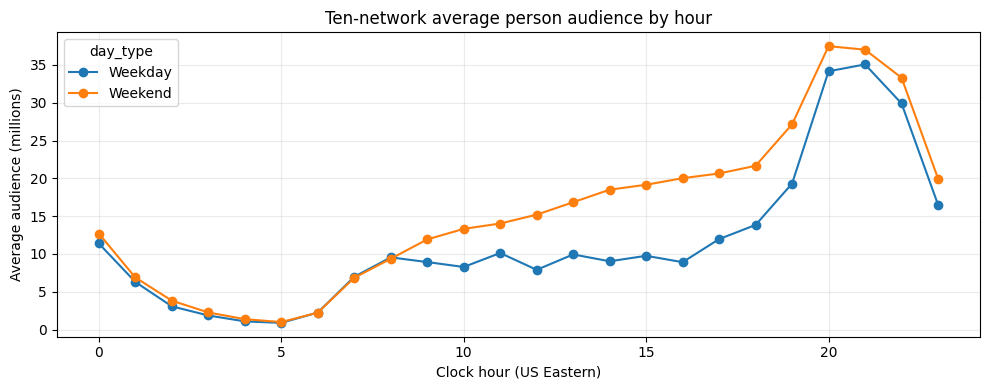

Peak hour, weekdays: 21
Peak hour, weekends: 20
Peak audience weekday/weekend (M): 35.08 37.49


In [3]:
# Split sessions at real clock-hour boundaries; classify every segment by broadcast day.
v_people = viewings.loc[viewings.resp_type.isin(["R", "L"])].copy()
pieces = []
for row in v_people[["respondent_id", "network_code", "start_ts", "end_ts"]].itertuples(index=False):
    cursor = row.start_ts
    while cursor < row.end_ts:
        stop = min(row.end_ts, cursor.floor("h") + pd.Timedelta(hours=1))
        bd = (cursor - pd.Timedelta(hours=6)).normalize()
        if pd.Timestamp("2024-10-01") <= bd <= pd.Timestamp("2024-10-31"):
            pieces.append((row.respondent_id, bd, cursor.hour, (stop-cursor).total_seconds()/60))
        cursor = stop
hourly_parts = pd.DataFrame(pieces, columns=["respondent_id", "broadcast_date", "hour", "minutes"])
hourly_parts = hourly_parts.merge(persons[["respondent_id", "broadcast_date", "weight"]],
                                  on=["respondent_id", "broadcast_date"], how="inner", validate="many_to_one")
hourly_parts["weighted_minutes"] = hourly_parts.minutes * hourly_parts.weight
hourly_parts["day_type"] = np.where(hourly_parts.broadcast_date.dt.dayofweek < 5, "Weekday", "Weekend")
days_by_type = dw[["broadcast_date"]].drop_duplicates().assign(
    day_type=lambda d: np.where(d.broadcast_date.dt.dayofweek < 5, "Weekday", "Weekend")
).groupby("day_type").size()
hour_chart = (hourly_parts.groupby(["day_type", "hour"]).weighted_minutes.sum()
              .div(days_by_type, level="day_type").div(60e6).unstack("day_type")
              .reindex(range(24)).fillna(0))
ax = hour_chart.plot(figsize=(10, 4), marker="o")
ax.set(xlabel="Clock hour (US Eastern)", ylabel="Average audience (millions)",
       title="Ten-network average person audience by hour")
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()
peak_weekday = int(hour_chart["Weekday"].idxmax())
peak_weekend = int(hour_chart["Weekend"].idxmax())
print("Peak hour, weekdays:", peak_weekday)
print("Peak hour, weekends:", peak_weekend)
print("Peak audience weekday/weekend (M):", round(hour_chart.loc[peak_weekday,"Weekday"],2),
      round(hour_chart.loc[peak_weekend,"Weekend"],2))

**Answer:** The weekday peak is 21:00 at 35.08 million average persons per minute, while the weekend peak is 20:00 at 37.49 million. Weekend viewing is stronger from late morning into evening, whereas weekday viewing rises more sharply into prime time; hours 00:00–05:59 use the preceding broadcast day.

## Task 1.3 — Session length

**Question:** Plot the distribution of person session length, weighting each session by its weight. Report the weighted mean and median. Why are they different, and which one would you put in a client deck?


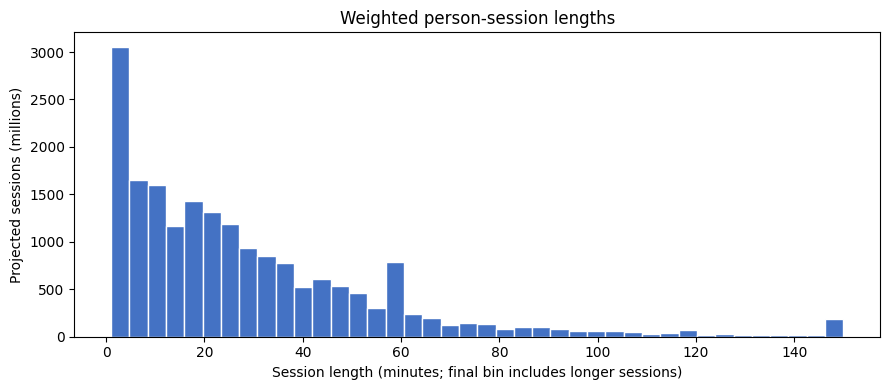

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [4]:
session = v_people.assign(length_min=(v_people.end_ts-v_people.start_ts).dt.total_seconds()/60)
session = session.loc[session.length_min.gt(0)].copy()
session["broadcast_date"] = (session.start_ts-pd.Timedelta(hours=6)).dt.normalize()
session = session.loc[session.broadcast_date.between("2024-10-01","2024-10-31")]
session = session.drop(columns=["weight"]).merge(persons[["respondent_id","broadcast_date","weight"]],
                        on=["respondent_id","broadcast_date"], how="inner", validate="many_to_one")
def weighted_percentile(values, weights, q):
    order = np.argsort(np.asarray(values))
    val, wt = np.asarray(values)[order], np.asarray(weights)[order]
    return float(val[np.searchsorted(np.cumsum(wt), q * wt.sum(), side="left")])
mean_length = np.average(session.length_min, weights=session.weight)
median_length = weighted_percentile(session.length_min, session.weight, .5)
upper = max(60, np.ceil(session.length_min.quantile(.99)/15)*15)
plt.figure(figsize=(9,4))
plt.hist(session.length_min.clip(upper=upper), bins=40, weights=session.weight/1e6,
         color="#4472c4", edgecolor="white")
plt.xlabel("Session length (minutes; final bin includes longer sessions)")
plt.ylabel("Projected sessions (millions)")
plt.title("Weighted person-session lengths")
plt.tight_layout()
plt.show()
print("Session length, weighted mean (min):", round(mean_length, 1))
print("Session length, weighted median (min):", round(median_length, 1))

**Answer:** The weighted mean session is 29.4 minutes and the median is 21.0 minutes because a long right tail raises the mean above the typical session. I would show the median and distribution in a client deck, while using the mean when estimating total viewing time.

## Task 2 — Program reach curve

Take all October telecasts of CBS Evening News (weekdays on CBS).

1. For each telecast compute the household rating, the P2+ rating and the projected audience in millions of persons.
2. In air order, compute the cumulative reach after each telecast for P2+, A18–34 and A18–49, and plot the three curves.
3. Why does cumulative reach keep growing while each telecast’s rating stays roughly flat? Which audience does the program reach best, and does that match what you know about who watches network evening news?


C:\Users\vivia\AppData\Local\Temp\ipykernel_22328\2646966804.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(news_table.round(2))


,telecast_id,broadcast_date,start_ts,episode_name,HH_rating_pct,P2+_rating_pct,P2+_audience_M
1108,1003837,2024-10-01,2024-10-01 18:30:00,Episode 268,3.47,1.67,5.28
1128,1003857,2024-10-02,2024-10-02 18:30:00,Episode 269,3.07,1.48,4.68
1148,1003877,2024-10-03,2024-10-03 18:30:00,Episode 270,2.99,1.47,4.68
1167,1003896,2024-10-04,2024-10-04 18:30:00,Episode 271,3.00,1.51,4.81
1207,1003936,2024-10-07,2024-10-07 18:30:00,Episode 273,3.06,1.52,4.83
1223,1003952,2024-10-08,2024-10-08 18:30:00,Episode 274,3.17,1.57,4.97
1241,1003970,2024-10-09,2024-10-09 18:30:00,Episode 275,2.98,1.48,4.70
1256,1003985,2024-10-10,2024-10-10 18:30:00,Episode 276,3.38,1.62,5.13
1272,1004001,2024-10-11,2024-10-11 18:30:00,Episode 277,3.09,1.48,4.69
1311,1004040,2024-10-14,2024-10-14 18:30:00,Episode 280,2.93,1.45,4.59


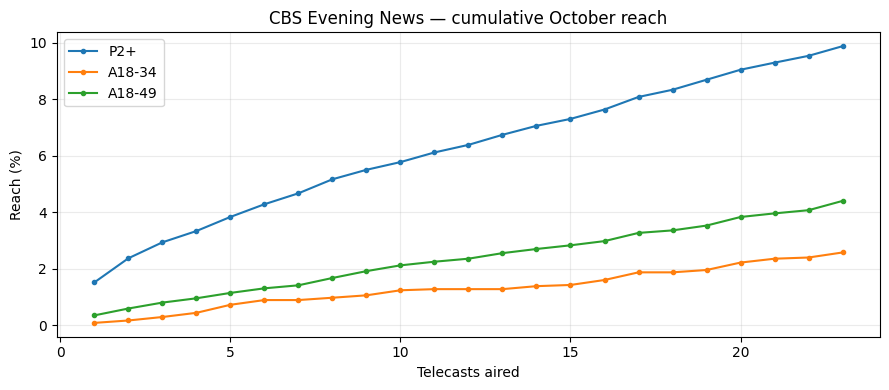

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4
Highest final reach among targets: P2+


In [5]:
news = (programs.loc[programs.network_code.eq("CBS") &
                     programs.program_name.eq("CBS Evening News") &
                     programs.broadcast_date.dt.dayofweek.lt(5) &
                     programs.broadcast_date.between("2024-10-01","2024-10-31")]
        .sort_values(["start_ts","telecast_id"]).copy())
assert len(news), "CBS Evening News telecasts were not found"
cbs_sessions = viewings.loc[viewings.network_code.eq("CBS") &
                           viewings.resp_type.isin(["H","R","L"])].copy()
def telecast_watchers(telecasts, sessions):
    out = []
    for t in telecasts.itertuples():
        overlap = sessions.loc[(sessions.start_ts < t.end_ts) & (sessions.end_ts > t.start_ts)].copy()
        mins = (np.minimum(overlap.end_ts.values.astype("datetime64[ns]"), np.datetime64(t.end_ts)) -
                np.maximum(overlap.start_ts.values.astype("datetime64[ns]"), np.datetime64(t.start_ts))) / np.timedelta64(1,"m")
        overlap = overlap.loc[mins >= 1, ["respondent_id","resp_type"]].drop_duplicates("respondent_id")
        overlap["telecast_id"] = t.telecast_id
        overlap["broadcast_date"] = t.broadcast_date
        out.append(overlap)
    return pd.concat(out, ignore_index=True)
news_watch = telecast_watchers(news, cbs_sessions)
news_watch = news_watch.merge(dw[["respondent_id","broadcast_date","weight"]],
                              on=["respondent_id","broadcast_date"], how="inner", validate="many_to_one")
den_h = homes.groupby("broadcast_date").weight.sum()
den_p = persons.groupby("broadcast_date").weight.sum()
h_audience = news_watch.loc[news_watch.resp_type.eq("H")].groupby("telecast_id").weight.sum()
p_audience = news_watch.loc[news_watch.resp_type.isin(["R","L"])].groupby("telecast_id").weight.sum()
news_table = news[["telecast_id","broadcast_date","start_ts","episode_name"]].copy()
news_table["HH_rating_pct"] = (100*news_table.telecast_id.map(h_audience).fillna(0) /
                                news_table.broadcast_date.map(den_h))
news_table["P2+_rating_pct"] = (100*news_table.telecast_id.map(p_audience).fillna(0) /
                                 news_table.broadcast_date.map(den_p))
news_table["P2+_audience_M"] = news_table.telecast_id.map(p_audience).fillna(0)/1e6
display(news_table.round(2))
news_ids = news_watch.loc[news_watch.resp_type.isin(["R","L"]), ["telecast_id","respondent_id"]]
reach_masks = {"P2+": monthly.age >= 2, "A18-34": monthly.age.between(18,34),
               "A18-49": monthly.age.between(18,49)}
reach_curves = {}
for label, mask in reach_masks.items():
    target = monthly.loc[mask, ["respondent_id","month_weight"]].set_index("respondent_id")
    seen = set()
    curve = []
    for tid in news.telecast_id:
        seen.update(news_ids.loc[news_ids.telecast_id.eq(tid),"respondent_id"].tolist())
        curve.append(100*target.loc[target.index.isin(seen),"month_weight"].sum()/target.month_weight.sum())
    reach_curves[label] = curve
reach_df = pd.DataFrame(reach_curves, index=range(1,len(news)+1))
reach_df.plot(figsize=(9,4), marker=".", title="CBS Evening News — cumulative October reach")
plt.xlabel("Telecasts aired"); plt.ylabel("Reach (%)"); plt.grid(alpha=.25); plt.tight_layout(); plt.show()
print("Telecasts of the program:", len(news))
print("Average household rating (%):", round(news_table.HH_rating_pct.mean(),1))
print("Average P2+ rating (%):", round(news_table["P2+_rating_pct"].mean(),1))
print("Average projected audience (M):", round(news_table["P2+_audience_M"].mean(),2))
print("Final reach P2+ (%):", round(reach_df["P2+"].iloc[-1],1))
print("Final reach A18-34 (%):", round(reach_df["A18-34"].iloc[-1],1))
print("Final reach A18-49 (%):", round(reach_df["A18-49"].iloc[-1],1))
print("Highest final reach among targets:", reach_df.iloc[-1].idxmax())

**Answer:** CBS Evening News has 23 weekday telecasts. Its average household rating is 3.2%, P2+ rating is 1.6%, and projected person audience is 4.93 million per telecast. A daily rating remains roughly level because it measures each airing separately; cumulative reach rises as new viewers join the exposed set. Final monthly reach is 9.9% for P2+, 4.4% for A18–49 and only 2.6% for A18–34. The program reaches the broad P2+ population best by percentage and under-reaches younger adults, consistent with an older-skewing evening-news audience.

## Task 3 — Program frequency

For The Young and the Restless (a daily soap on CBS), count for every person who watched how many of its October telecasts they saw: that is the program’s frequency, the same idea as ad frequency in Lecture 1. Use each person’s monthly weight from the rules.

1. Report the projected number of viewers (millions), and the weighted average and median frequency.
2. Plot the frequency distribution in projected viewers: how many millions watched 1, 2, 3, … telecasts.
3. What share of all projected views comes from the most loyal viewers? Define them as everyone whose frequency is at or above the weighted 80th percentile of frequency (whole frequency levels, no splitting). Is the average frequency a fair summary (“the average can lie”)?


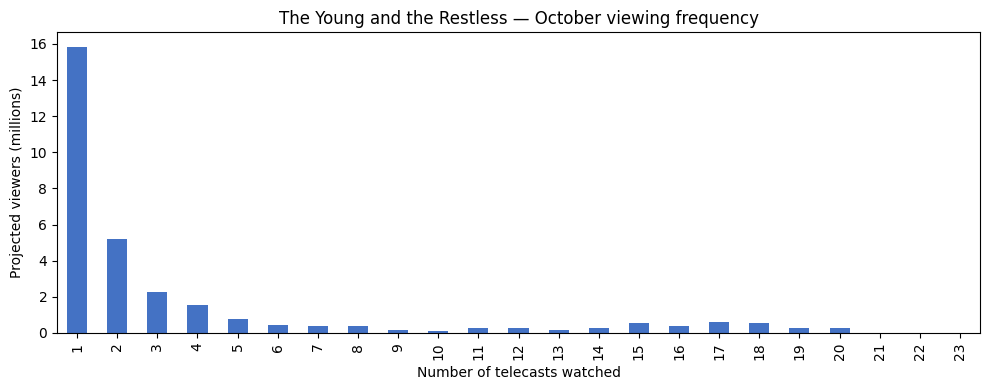

Projected viewers (M): 30.8
Average frequency (weighted): 3.63
Median frequency (weighted): 1.0
Share of views from the most loyal viewers: 0.704
Weighted 80th-percentile frequency level: 4


In [6]:
soap = (programs.loc[programs.network_code.eq("CBS") &
                     programs.program_name.eq("The Young and the Restless") &
                     programs.broadcast_date.between("2024-10-01","2024-10-31")]
        .sort_values(["start_ts","telecast_id"]))
assert len(soap), "Soap telecasts were not found"
soap_watch = telecast_watchers(soap, cbs_sessions.loc[cbs_sessions.resp_type.isin(["R","L"])])
soap_watch = soap_watch.merge(persons[["respondent_id","broadcast_date"]],
                              on=["respondent_id","broadcast_date"], how="inner").drop_duplicates(
                                  ["telecast_id","respondent_id"])
freq = (soap_watch.groupby("respondent_id").telecast_id.nunique().rename("frequency").reset_index()
        .merge(monthly[["respondent_id","month_weight"]], on="respondent_id", validate="one_to_one"))
frequency_dist = freq.groupby("frequency").month_weight.sum().reindex(range(1,len(soap)+1),fill_value=0)/1e6
ax = frequency_dist.plot.bar(figsize=(10,4), color="#4472c4")
ax.set(xlabel="Number of telecasts watched", ylabel="Projected viewers (millions)",
       title="The Young and the Restless — October viewing frequency")
plt.tight_layout(); plt.show()
avg_frequency = np.average(freq.frequency, weights=freq.month_weight)
med_frequency = weighted_percentile(freq.frequency,freq.month_weight,.5)
p80 = weighted_percentile(freq.frequency,freq.month_weight,.8)
loyal_view_share = ((freq.loc[freq.frequency.ge(p80),"frequency"] *
                     freq.loc[freq.frequency.ge(p80),"month_weight"]).sum() /
                    (freq.frequency*freq.month_weight).sum())
print("Projected viewers (M):", round(freq.month_weight.sum()/1e6,2))
print("Average frequency (weighted):", round(avg_frequency,2))
print("Median frequency (weighted):", round(med_frequency,2))
print("Share of views from the most loyal viewers:", round(loyal_view_share,3))
print("Weighted 80th-percentile frequency level:", int(p80))

**Answer:** The program reached a projected 30.80 million distinct people during October. Weighted average frequency is 3.63 telecasts, but the median is only one: the large one-time audience and a smaller repeat-viewing group have different behavior. The most loyal group starts at the weighted 80th-percentile level of four telecasts and generates 70.4% of all projected views (whole frequency levels are included). Therefore the average alone does not describe a typical viewer.

## Task 4 — Networks by age and gender

For each network compute projected viewing minutes (minutes × weight) for six audiences: M18–34, W18–34, M35–54, W35–54, M55+ and W55+. List the top 5 networks for each audience.

1. Which network has the youngest audience and which the oldest? Measure it as the share of each network’s projected minutes coming from 18–34 viewers.
2. Compute the same share once more without weights (raw panel minutes). Why is it different? What does it tell you about who is over- or under-represented in the panel, and what would go wrong if you reported raw panel numbers to a client?
3. **Bonus (+1 point):** One or two sentences: if you sold ads on the oldest network, how would you pitch it to an advertiser who wants young adults?


In [7]:
network_sessions = session[["respondent_id","network_code","length_min","weight"]].merge(
    demog, on="respondent_id", how="left", validate="many_to_one")
network_sessions = network_sessions.loc[network_sessions.age.ge(2) &
                                         network_sessions.sex.isin(["M","W"])].copy()
network_sessions["weighted_minutes"] = network_sessions.length_min * network_sessions.weight
network_sessions["age_band"] = pd.cut(network_sessions.age, [18,35,55,np.inf],
                                      right=False, labels=["18-34","35-54","55+"])
network_sessions["audience"] = network_sessions.sex + network_sessions.age_band.astype(str)
for audience in ["M18-34","W18-34","M35-54","W35-54","M55+","W55+"]:
    top = (network_sessions.loc[network_sessions.audience.eq(audience)]
           .groupby("network_code").weighted_minutes.sum().sort_values(ascending=False).head(5)/1e6)
    print(audience, "— top 5 networks, projected viewing minutes (M):")
    display(top.round(2).rename("minutes_M").to_frame())
by_network = network_sessions.groupby("network_code").agg(weighted_total=("weighted_minutes","sum"),
                                                          raw_total=("length_min","sum"))
young = network_sessions.loc[network_sessions.age.lt(35)].groupby("network_code").agg(
    weighted_young=("weighted_minutes","sum"),raw_young=("length_min","sum"))
age_shares = by_network.join(young).fillna(0)
age_shares["weighted_18_34_share"] = age_shares.weighted_young/age_shares.weighted_total
age_shares["raw_18_34_share"] = age_shares.raw_young/age_shares.raw_total
age_shares["raw_minus_weighted"] = age_shares.raw_18_34_share-age_shares.weighted_18_34_share
display(age_shares[["weighted_18_34_share","raw_18_34_share","raw_minus_weighted"]].sort_values(
    "weighted_18_34_share",ascending=False).round(3))
print("Youngest network:", age_shares.weighted_18_34_share.idxmax())
print("Oldest network:", age_shares.weighted_18_34_share.idxmin())
print("Network with largest raw-vs-weighted difference:",
      age_shares.raw_minus_weighted.abs().idxmax())

M18-34 — top 5 networks, projected viewing minutes (M):


,minutes_M
network_code,
FOX,4386.65
NBC,3910.39
CBS,3044.35
ABC,3010.78
FX,1473.96


W18-34 — top 5 networks, projected viewing minutes (M):


,minutes_M
network_code,
FOX,4574.44
NBC,4527.59
ABC,3504.86
CBS,2811.22
FX,1383.47


M35-54 — top 5 networks, projected viewing minutes (M):


...

,minutes_M
network_code,
CBS,38274.03
NBC,34267.41
FOX,30878.51
ABC,30793.34
FNC,27903.71


W55+ — top 5 networks, projected viewing minutes (M):


,minutes_M
network_code,
CBS,47120.32
NBC,41391.87
ABC,38840.01
FOX,36914.72
FNC,31450.73


,weighted_18_34_share,raw_18_34_share,raw_minus_weighted
network_code,,,
FX,0.359,0.315,-0.044
BRAVO,0.211,0.184,-0.027
FOOD,0.163,0.163,-0.000
FOX,0.163,0.166,0.003
NBC,0.147,0.149,0.002
ABC,0.138,0.145,0.007
HGTV,0.125,0.122,-0.002
CBS,0.109,0.115,0.006
HIST,0.090,0.090,-0.000


Youngest network: FX
Oldest network: FNC
Network with largest raw-vs-weighted difference: FX


**Answer:** FX has the youngest audience by the weighted 18–34 share of its person-minutes (0.359); FNC is the oldest (0.037). On FX the raw panel share is only 0.315, 0.044 below the weighted national estimate: younger FX viewers carry relatively higher weights and are under-represented in raw panel minutes. FNC has 0.040 raw versus 0.037 weighted. Reporting raw minutes would misstate target composition and could misprice or mis-target a campaign. The six printed top-five tables use projected minutes, not sample counts.

**Bonus answer:** I would present FNC honestly as an older-skewing network (only 3.7% of weighted minutes from ages 18–34). For a young-adult campaign I would offer only specific placements whose projected young-adult minutes and price meet the buyer's goal, rather than sell broad FNC reach as a youth audience.